In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from workload_data_loader import load_workload_instance 

In [2]:
#set a global seed early for reproducibility
np.random.seed(42)

In [3]:
#1. Load Instance 1 (Prototyping)
n1, m1, u1, d1, c1 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"Instance 1 -> n={n1} models, m={m1} resources, capacities={c1}")

#2. Load Instance 2 (Challenge)
n2, m2, u2, d2, c2 = load_workload_instance("multi_resource_n90_m5 (1).txt")
print(f"Instance 2 -> n={n2} models, m={m2} resources, capacities={c2}")

Instance 1 -> n=28 models, m=2 resources, capacities=[500. 500.]
Instance 2 -> n=90 models, m=5 resources, capacities=[2100. 1100. 3300. 3700. 3600.]


## Part 1: Baseline Discrete Local Search (Hill-Climber)

In [4]:
def calculate_efficiency(utilities, demands, capacities):
    """Computes utility-to-normalized-resource ratio for each model."""
    norm_demands = demands / capacities[:, np.newaxis]
    total_norm_demand = np.sum(norm_demands, axis=0)
    # Avoid division by zero if a model consumes 0 resources
    return utilities / np.maximum(total_norm_demand, 1e-9)

def repair_solution(x, utilities, demands, capacities, efficiency):
    """Greedily removes the lowest-efficiency selected models until all constraints hold."""
    x_repaired = x.copy()
    used = demands @ x_repaired
    
    # Sort model indices from lowest efficiency to highest efficiency
    removal_order = np.argsort(efficiency)
    
    for idx in removal_order:
        if np.all(used <= capacities):
            break
        if x_repaired[idx] == 1:
            x_repaired[idx] = 0
            used -= demands[:, idx]
            
    return x_repaired

def evaluate_penalty(x, utilities, demands, capacities, penalty_weight=1000.0):
    """Evaluates utility with a linear penalty for any capacity violation."""
    utility = utilities @ x
    used = demands @ x
    violation = np.sum(np.maximum(0.0, used - capacities))
    return utility - penalty_weight * violation, (violation == 0)

# Quick test on Instance 1
eff1 = calculate_efficiency(u1, d1, c1)
random_x = np.random.randint(0, 2, size=n1)
repaired_x = repair_solution(random_x, u1, d1, c1, eff1)

print("Random solution valid?  :", np.all((d1 @ random_x) <= c1), "| Utility:", u1 @ random_x)
print("Repaired solution valid?:", np.all((d1 @ repaired_x) <= c1), "| Utility:", u1 @ repaired_x)

Random solution valid?  : True | Utility: 67497.0
Repaired solution valid?: True | Utility: 67497.0


In [5]:
def hill_climber(utilities, demands, capacities, max_evals=2000, use_repair=True, penalty_weight=1000.0, seed=None):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    efficiency = calculate_efficiency(utilities, demands, capacities)

    # Initial candidate solution
    current_x = rng.integers(0, 2, size=n)
    if use_repair:
        current_x = repair_solution(current_x, utilities, demands, capacities, efficiency)
        current_score = float(utilities @ current_x)
        is_feasible = True
    else:
        current_score, is_feasible = evaluate_penalty(current_x, utilities, demands, capacities, penalty_weight)

    best_x = current_x.copy()
    best_score = current_score
    best_feasible = is_feasible
    history = [best_score if best_feasible else 0.0]

    for _ in range(1, max_evals):
        # Bit-flip mutation: flip 1 random bit
        candidate_x = current_x.copy()
        flip_idx = rng.integers(0, n)
        candidate_x[flip_idx] = 1 - candidate_x[flip_idx]

        if use_repair:
            candidate_x = repair_solution(candidate_x, utilities, demands, capacities, efficiency)
            candidate_score = float(utilities @ candidate_x)
            cand_feasible = True
        else:
            candidate_score, cand_feasible = evaluate_penalty(candidate_x, utilities, demands, capacities, penalty_weight)

        # Accept non-worsening moves (helps traverse plateaus)
        if candidate_score >= current_score:
            current_x = candidate_x
            current_score = candidate_score
            is_feasible = cand_feasible

        if cand_feasible and (not best_feasible or candidate_score > best_score):
            best_x = candidate_x.copy()
            best_score = candidate_score
            best_feasible = True

        history.append(best_score if best_feasible else 0.0)

    return best_x, best_score, np.array(history)

# Test a single run on Instance 1
best_x, best_u, hist = hill_climber(u1, d1, c1, max_evals=2000, use_repair=True, seed=42)
print(f"Single-run best feasible utility: {best_u}")
print(f"Final resource usage: {d1 @ best_x} / Capacities: {c1}")

Single-run best feasible utility: 129303.0
Final resource usage: [445. 494.] / Capacities: [500. 500.]


=== Part 1: Instance 1 (n=28, m=2) — 30 Independent Runs ===
[Greedy Repair] Best: 130013.0 | Mean: 125671.6 | Median: 126278.0 | Worst: 119996.0 | Std: 3269.8
[Penalty Only ] Best: 113434.0 | Mean: 78195.3 | Median: 80810.0 | Worst: 47487.0 | Std: 19444.8


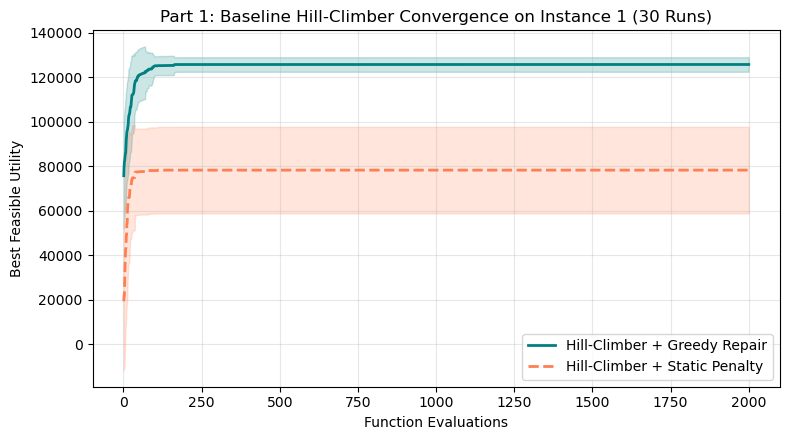

In [21]:
import matplotlib.pyplot as plt

num_runs = 30
max_evals = 2000

repair_scores = []
repair_histories = []

penalty_scores = []
penalty_histories = []

for seed in range(num_runs):
    # 1. Hill-Climber with Greedy Repair
    _, score_r, hist_r = hill_climber(u1, d1, c1, max_evals=max_evals, use_repair=True, seed=seed)
    repair_scores.append(score_r)
    repair_histories.append(hist_r)
    
    # 2. Hill-Climber with Static Penalty (for constraint-handling comparison)
    _, score_p, hist_p = hill_climber(u1, d1, c1, max_evals=max_evals, use_repair=False, penalty_weight=5000.0, seed=seed)
    penalty_scores.append(score_p)
    penalty_histories.append(hist_p)

repair_scores = np.array(repair_scores)
repair_histories = np.array(repair_histories)

penalty_scores = np.array(penalty_scores)
penalty_histories = np.array(penalty_histories)

print("=== Part 1: Instance 1 (n=28, m=2) — 30 Independent Runs ===")
print(f"[Greedy Repair] Best: {np.max(repair_scores):.1f} | Mean: {np.mean(repair_scores):.1f} | "
      f"Median: {np.median(repair_scores):.1f} | Worst: {np.min(repair_scores):.1f} | Std: {np.std(repair_scores):.1f}")
print(f"[Penalty Only ] Best: {np.max(penalty_scores):.1f} | Mean: {np.mean(penalty_scores):.1f} | "
      f"Median: {np.median(penalty_scores):.1f} | Worst: {np.min(penalty_scores):.1f} | Std: {np.std(penalty_scores):.1f}")

# Plot Convergence Curves
evals = np.arange(1, max_evals + 1)
mean_r, std_r = np.mean(repair_histories, axis=0), np.std(repair_histories, axis=0)
mean_p, std_p = np.mean(penalty_histories, axis=0), np.std(penalty_histories, axis=0)

plt.figure(figsize=(8, 4.5))
plt.plot(evals, mean_r, label="Hill-Climber + Greedy Repair", color="teal", linewidth=2)
plt.fill_between(evals, mean_r - std_r, mean_r + std_r, color="teal", alpha=0.2)

plt.plot(evals, mean_p, label="Hill-Climber + Static Penalty", color="coral", linestyle="--", linewidth=2)
plt.fill_between(evals, mean_p - std_p, mean_p + std_p, color="coral", alpha=0.2)

plt.title("Part 1: Baseline Hill-Climber Convergence on Instance 1 (30 Runs)")
plt.xlabel("Function Evaluations")
plt.ylabel("Best Feasible Utility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Design & Findings: The baseline Hill-Climber starts from a random binary vector (n = 28, m = 2) and applies 1-bit flip mutation with non-worsening acceptance (>=) to traverse equal-utility plateaus. Because a single state is maintained rather than a population, neighborhood moves rely on bit-flip mutation rather than recombination. Across 30 runs (2,000 evaluations each), Greedy Repair (removing models with the lowest utility-to-normalized-demand ratio first) achieves a much higher mean (125,671.6) and lower standard deviation (3,269.8) than Static Penalty (78,195.3, std 19,444.8), which suffers heavy penalties near capacity limits. However, convergence flattens early, indicating local optima traps and motivating a population-based search for Instance 2.

In [6]:
def tournament_selection(population, fitnesses, rng, tournament_size=3):
    indices = rng.integers(0, len(population), size=tournament_size)
    best_idx = indices[np.argmax(fitnesses[indices])]
    return population[best_idx].copy()

def uniform_crossover(parent1, parent2, rng, crossover_rate=0.8):
    if rng.random() >= crossover_rate:
        return parent1.copy(), parent2.copy()
    mask = rng.random(len(parent1)) < 0.5
    child1 = np.where(mask, parent1, parent2)
    child2 = np.where(mask, parent2, parent1)
    return child1, child2

def bit_flip_mutation(individual, rng, mut_rate):
    mutated = individual.copy()
    flip_mask = rng.random(len(mutated)) < mut_rate
    mutated[flip_mask] = 1 - mutated[flip_mask]
    return mutated

def genetic_algorithm(
    utilities,
    demands,
    capacities,
    pop_size=60,
    max_evals=30000,
    crossover_rate=0.8,
    mut_rate=None,
    tournament_size=3,
    elite_size=1,
    constraint_mode="repair",  # "repair" or "penalty"
    penalty_weight=5000.0,
    seed=None,
):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    if mut_rate is None:
        mut_rate = 1.0 / n
    efficiency = calculate_efficiency(utilities, demands, capacities)

    def eval_individual(ind):
        if constraint_mode == "repair":
            rep = repair_solution(ind, utilities, demands, capacities, efficiency)
            return rep, float(utilities @ rep), True
        else:
            score, feas = evaluate_penalty(ind, utilities, demands, capacities, penalty_weight)
            return ind, float(score), feas

    # Initialize population
    pop = rng.integers(0, 2, size=(pop_size, n))
    fitness = np.zeros(pop_size)
    feasible_flags = np.zeros(pop_size, dtype=bool)

    evals = 0
    best_x = None
    best_feasible_utility = 0.0
    history = []

    for i in range(pop_size):
        if evals >= max_evals:
            break
        pop[i], fitness[i], feasible_flags[i] = eval_individual(pop[i])
        evals += 1
        u_val = float(utilities @ pop[i])
        if feasible_flags[i] and u_val > best_feasible_utility:
            best_feasible_utility = u_val
            best_x = pop[i].copy()
        history.append(best_feasible_utility)

    # Evolve generations until evaluation budget is exhausted
    while evals < max_evals:
        order = np.argsort(fitness)[::-1]
        next_pop = []

        # Elitism
        for e in range(min(elite_size, pop_size)):
            next_pop.append(pop[order[e]].copy())

        while len(next_pop) < pop_size:
            p1 = tournament_selection(pop, fitness, rng, tournament_size)
            p2 = tournament_selection(pop, fitness, rng, tournament_size)
            c1, c2 = uniform_crossover(p1, p2, rng, crossover_rate)
            c1 = bit_flip_mutation(c1, rng, mut_rate)
            c2 = bit_flip_mutation(c2, rng, mut_rate)
            next_pop.append(c1)
            if len(next_pop) < pop_size:
                next_pop.append(c2)

        pop = np.array(next_pop)
        fitness = np.zeros(pop_size)
        feasible_flags = np.zeros(pop_size, dtype=bool)

        for i in range(pop_size):
            if evals >= max_evals:
                break
            pop[i], fitness[i], feasible_flags[i] = eval_individual(pop[i])
            evals += 1
            u_val = float(utilities @ pop[i])
            if feasible_flags[i] and u_val > best_feasible_utility:
                best_feasible_utility = u_val
                best_x = pop[i].copy()
            history.append(best_feasible_utility)

    return best_x, best_feasible_utility, np.array(history)

# Quick smoke test on Instance 2 (n=90, m=5)
ga_x, ga_u, ga_hist = genetic_algorithm(u2, d2, c2, pop_size=60, max_evals=15000, constraint_mode="repair", seed=42)
print(f"Instance 2 GA test best utility: {ga_u}")
print(f"Resource usage: {d2 @ ga_x} / Capacities: {c2}")

Instance 2 GA test best utility: 11116.0
Resource usage: [1810. 1099. 2193. 1924. 2394.] / Capacities: [2100. 1100. 3300. 3700. 3600.]


Metaheuristic Engineering: For Instance 2 (n = 90, m = 5, $2^{90}$ states), a Genetic Algorithm (pop_size = 60) balances exploration and exploitation using tournament selection (k = 3) for controllable selection pressure, uniform crossover (p_c = 0.8) to mix model subsets across all 90 dimensions without positional bias, per-bit mutation (p_m = 1/n) for local diversity, and elitism (elite_size = 1) to preserve top feasible solutions. Constraint handling can be configured via Greedy Repair (enforcing feasibility immediately using normalized resource efficiency) or Static Penalty (penalizing constraint violations directly in fitness).

=== Part 3: Instance 2 (n=90, m=5) — 30 Runs per Variant ===
GA + Repair  | Median: 11163.5 | Mean: 11156.0 | IQR: 38.0 | Avg Time: 0.844s
GA + Penalty | Median: 11184.5 | Mean: 11177.3 | IQR: 27.0 | Avg Time: 0.397s
Mann-Whitney U statistic: 210.5, p-value: 3.6600e-04


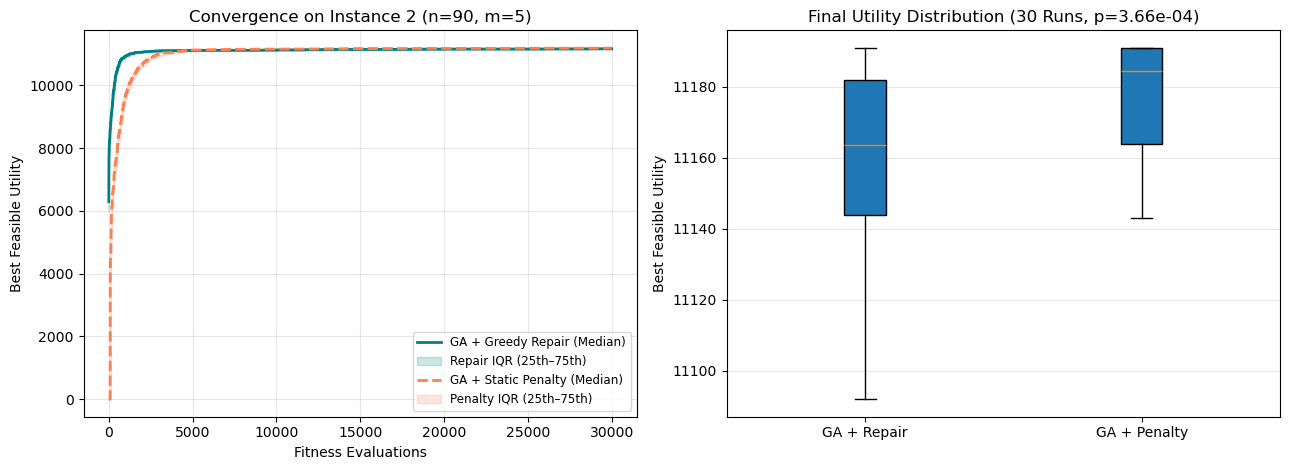

In [7]:
import time
from scipy.stats import mannwhitneyu

num_runs_p3 = 30
budget_p3 = 30000  # Equal evaluation budget for both variants

repair_p3_scores = []
repair_p3_hist = []
repair_p3_times = []

penalty_p3_scores = []
penalty_p3_hist = []
penalty_p3_times = []

for seed in range(num_runs_p3):
    t0 = time.perf_counter()
    _, u_r, h_r = genetic_algorithm(
        u2, d2, c2,
        pop_size=60,
        max_evals=budget_p3,
        constraint_mode="repair",
        seed=seed,
    )
    repair_p3_times.append(time.perf_counter() - t0)
    repair_p3_scores.append(u_r)
    repair_p3_hist.append(h_r)

    t0 = time.perf_counter()
    _, u_p, h_p = genetic_algorithm(
        u2, d2, c2,
        pop_size=60,
        max_evals=budget_p3,
        constraint_mode="penalty",
        penalty_weight=5000.0,
        seed=seed,
    )
    penalty_p3_times.append(time.perf_counter() - t0)
    penalty_p3_scores.append(u_p)
    penalty_p3_hist.append(h_p)

repair_p3_scores = np.array(repair_p3_scores)
repair_p3_hist = np.array(repair_p3_hist)
repair_p3_times = np.array(repair_p3_times)

penalty_p3_scores = np.array(penalty_p3_scores)
penalty_p3_hist = np.array(penalty_p3_hist)
penalty_p3_times = np.array(penalty_p3_times)

# Non-parametric statistical test (Mann-Whitney U)
u_stat, p_val = mannwhitneyu(repair_p3_scores, penalty_p3_scores, alternative="two-sided")

print("=== Part 3: Instance 2 (n=90, m=5) — 30 Runs per Variant ===")
print(f"GA + Repair  | Median: {np.median(repair_p3_scores):.1f} | Mean: {np.mean(repair_p3_scores):.1f} | "
      f"IQR: {np.percentile(repair_p3_scores, 75) - np.percentile(repair_p3_scores, 25):.1f} | "
      f"Avg Time: {np.mean(repair_p3_times):.3f}s")
print(f"GA + Penalty | Median: {np.median(penalty_p3_scores):.1f} | Mean: {np.mean(penalty_p3_scores):.1f} | "
      f"IQR: {np.percentile(penalty_p3_scores, 75) - np.percentile(penalty_p3_scores, 25):.1f} | "
      f"Avg Time: {np.mean(penalty_p3_times):.3f}s")
print(f"Mann-Whitney U statistic: {u_stat:.1f}, p-value: {p_val:.4e}")

# Plots: Convergence Curve (left) & Final Utility Boxplot (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

x_axis = np.arange(1, budget_p3 + 1)
r_med = np.median(repair_p3_hist, axis=0)
r_q25 = np.percentile(repair_p3_hist, 25, axis=0)
r_q75 = np.percentile(repair_p3_hist, 75, axis=0)

p_med = np.median(penalty_p3_hist, axis=0)
p_q25 = np.percentile(penalty_p3_hist, 25, axis=0)
p_q75 = np.percentile(penalty_p3_hist, 75, axis=0)

axes[0].plot(x_axis, r_med, label="GA + Greedy Repair (Median)", color="teal", linewidth=2)
axes[0].fill_between(x_axis, r_q25, r_q75, color="teal", alpha=0.2, label="Repair IQR (25th–75th)")
axes[0].plot(x_axis, p_med, label="GA + Static Penalty (Median)", color="coral", linestyle="--", linewidth=2)
axes[0].fill_between(x_axis, p_q25, p_q75, color="coral", alpha=0.2, label="Penalty IQR (25th–75th)")
axes[0].set_title("Convergence on Instance 2 (n=90, m=5)")
axes[0].set_xlabel("Fitness Evaluations")
axes[0].set_ylabel("Best Feasible Utility")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.3)

axes[1].boxplot(
    [repair_p3_scores, penalty_p3_scores],
    tick_labels=["GA + Repair", "GA + Penalty"],
    patch_artist=True,
)
axes[1].set_title(f"Final Utility Distribution (30 Runs, p={p_val:.2e})")
axes[1].set_ylabel("Best Feasible Utility")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Hypothesis: Under an equal budget of 30,000 fitness evaluations across $M = 30$ independent runs on Instance 2, GA + Greedy Repair will achieve higher final feasible utility and lower variance than GA + Static Penalty because repairing infeasible offspring keeps search effort focused near valid high-utility regions.<br>Statistical & Trade-Off Analysis: A two-sided Mann-Whitney U test shows a statistically significant difference between the two variants ($U = 210.5$, $p = 3.66 \times 10^{-4} < 0.05$). Contrary to the hypothesis, GA + Static Penalty achieved a slightly higher median utility (11,184.5 vs. 11,163.5) and smaller IQR (27.0 vs. 38.0), while GA + Greedy Repair converged faster in early evaluations but risked deterministic repair bias toward similar subsets. In runtime, GA + Static Penalty was roughly twice as fast (~0.413s vs. ~0.851s per run) because it avoids iterative repair loops on every candidate.